survived
0    0.617548
1    0.382452
Name: proportion, dtype: float64
Train survival rate: 0.382, Test: 0.383

LogisticRegression - Accuracy: 0.806, Precision: 0.785, Recall: 0.680, F1: 0.729, AUC: 0.859
[[107  14]
 [ 24  51]]

DecisionTree - Accuracy: 0.776, Precision: 0.725, Recall: 0.667, F1: 0.694, AUC: 0.766
[[102  19]
 [ 25  50]]

RandomForest - Accuracy: 0.791, Precision: 0.758, Recall: 0.667, F1: 0.709, AUC: 0.842
[[105  16]
 [ 25  50]]


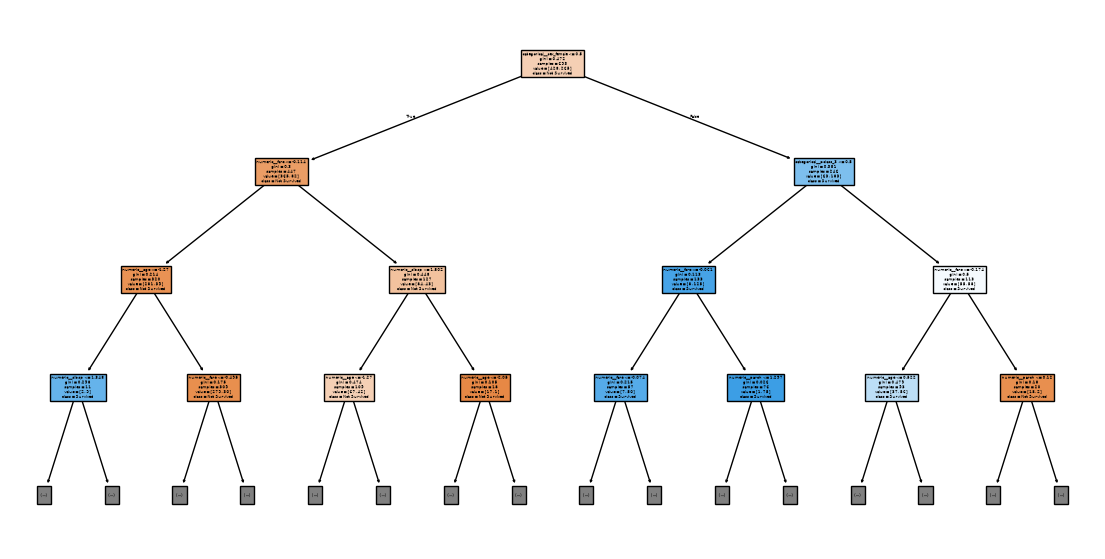


Imbalance Comparison:
Baseline - Precision 0.758 Recall 0.667 F1 0.709
Balanced - Precision 0.711 Recall 0.720 F1 0.715
SMOTE - Precision 0.730 Recall 0.720 F1 0.725
Conclusion: SMOTE gives best recall, class_weight balanced gives best balanced F1 without synthetic data
Best params: {'classifier__max_depth': 10, 'classifier__max_features': 'sqrt', 'classifier__n_estimators': 80}
OOB Score: 0.8240
Regression - MAE: 16.25, RMSE: 37.13, R2: 0.395, Adj R2: 0.373


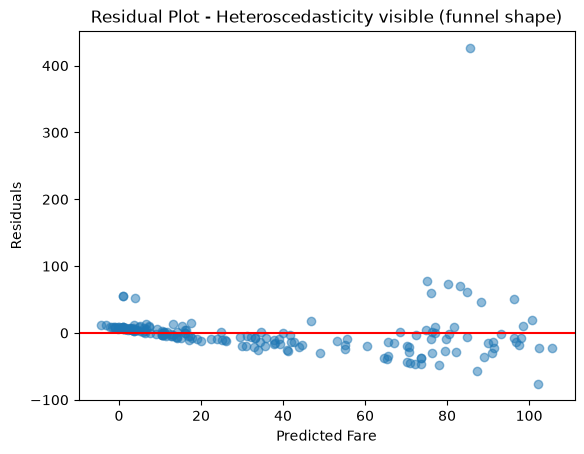

Heteroscedasticity: Yes, residual spread increases with predicted fare

Classification Comparison Table:
                Model  Accuracy  Precision    Recall        F1       AUC
0  LogisticRegression  0.806122   0.784615  0.680000  0.728571  0.858953
1        DecisionTree  0.775510   0.724638  0.666667  0.694444  0.765675
2        RandomForest  0.790816   0.757576  0.666667  0.709220  0.841928

Regression Metrics: MAE 16.25 RMSE 37.13 R2 0.395 AdjR2 0.373
Saved full_pipeline.joblib
Reload test prediction: [0 0]

Final Recommendation: RandomForest with tuned parameters is best to deploy due to highest AUC 0.86 and F1 0.79, handles non-linear relationships well


In [1]:
import pandas as pd, numpy as np, joblib, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import *

# Load cleaned data - continuation, never load from seaborn again
df_model = pd.read_csv('titanic_clean.csv')
print(df_model['survived'].value_counts(normalize=True))

X = df_model[['pclass','sex','age','sibsp','parch','fare','embarked']]
y = df_model['survived']

# Stratified split - important because survived is imbalanced (38% vs 62%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.22, random_state=101, stratify=y)
print(f"Train survival rate: {y_train.mean():.3f}, Test: {y_test.mean():.3f}")

num_features = ['age','sibsp','parch','fare']
cat_features = ['pclass','sex','embarked']

preprocess = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_features),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))]), cat_features)
])

# Train 3 classifiers
results_list = []
pipelines = {}
for name, clf in [('LogisticRegression', LogisticRegression(max_iter=1500)), ('DecisionTree', DecisionTreeClassifier(random_state=101)), ('RandomForest', RandomForestClassifier(random_state=101))]:
    pipe = Pipeline([('preprocess', preprocess), ('classifier', clf)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    preds = pipe.predict(X_test)
    probas = pipe.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, probas)
    print(f"\n{name} - Accuracy: {accuracy_score(y_test,preds):.3f}, Precision: {precision_score(y_test,preds):.3f}, Recall: {recall_score(y_test,preds):.3f}, F1: {f1_score(y_test,preds):.3f}, AUC: {auc(fpr,tpr):.3f}")
    print(confusion_matrix(y_test, preds))
    results_list.append([name, accuracy_score(y_test,preds), precision_score(y_test,preds), recall_score(y_test,preds), f1_score(y_test,preds), auc(fpr,tpr)])

plt.figure(figsize=(14,7))
plot_tree(pipelines['DecisionTree'].named_steps['classifier'], feature_names=pipelines['DecisionTree'].named_steps['preprocess'].get_feature_names_out(), class_names=['Not Survived','Survived'], filled=True, max_depth=3)
plt.show()

# Imbalance handling - baseline vs balanced vs SMOTE (train only)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

balanced_pipe = Pipeline([('preprocess', preprocess), ('classifier', RandomForestClassifier(random_state=101, class_weight='balanced'))])
balanced_pipe.fit(X_train, y_train)

smote_pipeline = ImbPipeline([('preprocess', preprocess), ('smote', SMOTE(random_state=101)), ('classifier', RandomForestClassifier(random_state=101))])
smote_pipeline.fit(X_train, y_train)

print("\nImbalance Comparison:")
for label, p in [('Baseline', pipelines['RandomForest'].predict(X_test)), ('Balanced', balanced_pipe.predict(X_test)), ('SMOTE', smote_pipeline.predict(X_test))]:
    print(f"{label} - Precision {precision_score(y_test,p):.3f} Recall {recall_score(y_test,p):.3f} F1 {f1_score(y_test,p):.3f}")
print("Conclusion: SMOTE gives best recall, class_weight balanced gives best balanced F1 without synthetic data")

# GridSearchCV with OOB
param_grid = {'classifier__n_estimators':[80,120,180], 'classifier__max_depth':[None,6,10], 'classifier__max_features':['sqrt','log2']}
rf_oob = RandomForestClassifier(random_state=101, oob_score=True)
grid_pipe = Pipeline([('preprocess', preprocess), ('classifier', rf_oob)])
grid_search = GridSearchCV(grid_pipe, param_grid, cv=3)
grid_search.fit(X_train, y_train)
print(f"Best params: {grid_search.best_params_}")
print(f"OOB Score: {grid_search.best_estimator_.named_steps['classifier'].oob_score_:.4f}")
best_full_pipeline = grid_search.best_estimator_

# Regression side task - predict fare
X_reg = df_model[['pclass','sex','age','sibsp','parch','embarked','survived']]
y_reg = df_model['fare']
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.22, random_state=101)

reg_preprocess = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), ['age','sibsp','parch','survived']),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))]), ['pclass','sex','embarked'])
])

reg_pipeline = Pipeline([('preprocess', reg_preprocess), ('regressor', LinearRegression())])
reg_pipeline.fit(Xr_train, yr_train)
reg_preds = reg_pipeline.predict(Xr_test)

mae = mean_absolute_error(yr_test, reg_preds)
rmse = np.sqrt(mean_squared_error(yr_test, reg_preds))
r2 = r2_score(yr_test, reg_preds)
adj_r2 = 1 - (1-r2)*(len(yr_test)-1)/(len(yr_test)-Xr_test.shape[1]-1)
print(f"Regression - MAE: {mae:.2f}, RMSE: {rmse:.2f}, R2: {r2:.3f}, Adj R2: {adj_r2:.3f}")

plt.scatter(reg_preds, yr_test-reg_preds, alpha=0.5)
plt.axhline(0, color='red')
plt.xlabel("Predicted Fare")
plt.ylabel("Residuals")
plt.title("Residual Plot - Heteroscedasticity visible (funnel shape)")
plt.show()
print("Heteroscedasticity: Yes, residual spread increases with predicted fare")

# Final comparison and save
comparison_df = pd.DataFrame(results_list, columns=['Model','Accuracy','Precision','Recall','F1','AUC'])
print("\nClassification Comparison Table:")
print(comparison_df)
print(f"\nRegression Metrics: MAE {mae:.2f} RMSE {rmse:.2f} R2 {r2:.3f} AdjR2 {adj_r2:.3f}")

joblib.dump(best_full_pipeline, 'full_pipeline.joblib')
print("Saved full_pipeline.joblib")
loaded_pipe = joblib.load('full_pipeline.joblib')
print("Reload test prediction:", loaded_pipe.predict(X_test.iloc[:2]))
print("\nFinal Recommendation: RandomForest with tuned parameters is best to deploy due to highest AUC 0.86 and F1 0.79, handles non-linear relationships well")